<a href="https://colab.research.google.com/github/wawaelenti/Machine-Learning/blob/main/DBSCAN_Perbandingan_Distance_Metric.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Metrik jarak dan prinsip DBSCAN

**Euclidean**
$$d(x,y)=\sqrt{\sum_i(x_i-y_i)^2}.$$

**Manhattan**
$$d(x,y)=\sum_i\lvert x_i-y_i\rvert.$$

**Cosine**
$$d(x,y)=1-\frac{x\cdot y}{\lVert x\rVert_2\lVert y\rVert_2}.$$

DBSCAN membentuk klaster dari lingkungan padat:
$$N_\varepsilon(x)=\{y:d(x,y)\leq\varepsilon\},\qquad
\lvert N_\varepsilon(x)\rvert\geq\mathrm{min\_samples}.$$

Titik sendiri ikut dihitung. Label `-1` menunjukkan noise. Semua metrik menggunakan data hasil StandardScaler dan parameter yang sama. PCA hanya untuk visualisasi.


In [ ]:
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# =======================================================================
# 1. SETUP & IMPORT LIBRARY
# =======================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

import gc
import time
import tracemalloc

from sklearn.metrics import pairwise_distances

from sklearn.neighbors import NearestNeighbors
from sklearn import config_context

from itertools import combinations

from IPython.display import HTML, display as _display
# Tabel lebar tetap dapat dibaca dengan geser horizontal.
def display(*objects):
    for obj in objects:
        if isinstance(obj, pd.DataFrame):
            _display(HTML('<div style="overflow-x:auto">'+obj.to_html(index=False)+'</div>'))
        else:
            _display(obj)


In [ ]:
# =======================================================================
# 2. DATASET & PREPROCESSING BERSAMA
# =======================================================================
FILE = 'dataset_B_05_2020 (1).csv'
df = pd.read_csv(FILE)

print('Shape dataset:', df.shape)
print('Jumlah data:', df.shape[0])
print('Jumlah kolom:', df.shape[1])
display(df.head(3))

# Metadata dan label asli disimpan terpisah dari fitur clustering.
urls = df['url'].copy()
y_true = df['status'].copy()
labels = y_true.copy()
X = df.drop(columns=['url', 'status']).select_dtypes(include=np.number)
print('Shape fitur numerik:', X.shape)

# Imputasi median, penghapusan fitur konstan, lalu StandardScaler.
print('Missing value sebelum imputasi:', int(X.isna().sum().sum()))
X = X.fillna(X.median())
print('Missing value setelah imputasi:', int(X.isna().sum().sum()))

selector = VarianceThreshold(threshold=0)
X_sel = selector.fit_transform(X)
selected_features = X.columns[selector.get_support()]
removed_features = X.columns[~selector.get_support()]
X_selected = pd.DataFrame(X_sel, columns=selected_features, index=X.index)
print('Fitur konstan yang dihapus:', list(removed_features))
print('Shape setelah seleksi fitur:', X_selected.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
df_after = pd.DataFrame(X_scaled, columns=selected_features, index=X.index)
print('Shape setelah StandardScaler:', X_scaled.shape)
display(df_after.head(3))


Shape dataset: (11430, 89)
Jumlah data: 11430
Jumlah kolom: 89


url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,nb_underscore,nb_tilde,nb_percent,nb_slash,nb_star,nb_colon,nb_comma,nb_semicolumn,nb_dollar,nb_space,nb_www,nb_com,nb_dslash,http_in_path,https_token,ratio_digits_url,ratio_digits_host,punycode,port,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,path_extension,nb_redirection,nb_external_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_words_raw,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,ratio_nullHyperlinks,nb_extCSS,ratio_intRedirection,ratio_extRedirection,ratio_intErrors,ratio_extErrors,login_form,external_favicon,links_in_tags,submit_email,ratio_intMedia,ratio_extMedia,sfh,iframe,popup_window,safe_anchor,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,0,0,0,0,3,0,1,0,0,0,0,1,0,0,0,1,0.000000,0.0,0,0,0,0,0,3,0,0,0,0,0,0,4,4,3,3,3,11,11,6,5.75,7.0,4.500000,0,0,0,0,0,0,17,0.529412,0.470588,0,0,0,0.875,0,0.5,0,0,80.0,0,100.0,0.0,0,0,0,0.0,0,0,0,0,1,0,45,-1,0,1,1,4,legitimate
http://shadetreetechnology.com/V4/validation/a111aedc8ae390eabcfa130e041a10a4,77,23,1,1,0,0,0,0,0,0,0,0,0,5,0,1,0,0,0,0,0,0,0,0,1,0.220779,0.0,0,0,0,0,0,1,0,0,0,0,1,0,4,4,2,19,2,32,19,32,15.75,19.0,14.666667,0,0,0,0,0,0,30,0.966667,0.033333,0,0,0,0.000,0,0.0,0,0,100.0,0,80.0,20.0,0,0,0,100.0,0,0,0,1,0,0,77,5767,0,0,1,2,phishing
https://support-appleld.com.secureupdate.duilawyeryork.com/ap/89e6a3b4b063b8d/?cmd=_update&dispatch=89e6a3b4b063b8d1b&locale=_,126,50,1,4,1,0,1,2,0,3,2,0,0,5,0,1,0,0,0,0,0,1,0,0,0,0.150794,0.0,0,0,0,1,0,3,1,0,0,0,1,0,12,2,2,3,2,17,13,17,8.25,8.4,8.142857,0,0,0,0,0,0,4,1.000000,0.000000,0,0,0,0.000,0,0.0,0,0,100.0,0,0.0,0.0,0,0,0,100.0,0,0,0,1,0,0,14,4004,5828815,0,1,0,phishing


Shape fitur numerik: (11430, 87)
Missing value sebelum imputasi: 0
Missing value setelah imputasi: 0
Fitur konstan yang dihapus: ['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']
Shape setelah seleksi fitur: (11430, 81)
Shape setelah StandardScaler: (11430, 81)


length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,nb_underscore,nb_tilde,nb_percent,nb_slash,nb_star,nb_colon,nb_comma,nb_semicolumn,nb_dollar,nb_space,nb_www,nb_com,nb_dslash,http_in_path,https_token,ratio_digits_url,ratio_digits_host,punycode,port,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,path_extension,nb_redirection,nb_external_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_words_raw,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,nb_extCSS,ratio_extRedirection,ratio_extErrors,login_form,external_favicon,links_in_tags,ratio_intMedia,ratio_extMedia,iframe,popup_window,safe_anchor,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
-0.436327,-0.193964,-0.421020,0.379116,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,-0.081815,-0.083946,-0.685161,-0.026465,-0.116135,-0.038984,-0.104139,-0.024962,-0.092717,1.098907,-0.337729,-0.081271,-0.098673,0.798018,-0.594651,-0.267868,-0.01871,-0.04866,-0.264999,-0.229732,-0.148617,1.206090,-0.503825,-0.301425,-0.375276,-0.013229,-0.720143,-0.05621,-0.400711,0.224909,-0.057562,-0.512450,0.200505,-0.198974,0.107876,-0.197666,-0.363968,-0.189497,-0.082894,-0.388973,-0.341057,-0.064257,-0.070168,-0.13514,-0.180392,-0.420926,-0.194034,0.605943,-0.284507,2.687711,2.801064,-0.260624,-0.890315,0.674877,1.235290,-0.605350,-0.03625,-0.077932,-0.948614,-0.033744,-0.03744,-0.377549,-1.860473,1.129194,-0.28037,-0.549299,-1.307594,-0.429340,6.978227,0.934264,0.320974
0.287067,0.177207,2.375182,-1.081136,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,-0.081815,-0.083946,0.377443,-0.026465,-0.116135,-0.038984,-0.104139,-0.024962,-0.092717,-0.893559,-0.337729,-0.081271,-0.098673,0.798018,1.876053,-0.267868,-0.01871,-0.04866,-0.264999,-0.229732,-0.148617,-1.933425,-0.503825,-0.301425,-0.375276,-0.013229,0.725201,-0.05621,-0.400711,0.224909,-0.509749,3.547014,-0.133086,0.751998,1.730002,0.929003,2.048202,3.164071,1.339666,-0.388973,-0.341057,-0.064257,-0.070168,-0.13514,-0.180392,-0.342965,0.967464,-0.760717,-0.284507,-0.596511,-0.399922,-0.260624,-0.890315,1.156557,0.802838,-0.084312,-0.03625,-0.077932,1.610785,-0.033744,-0.03744,-0.377549,0.537498,-0.885587,-0.28037,-0.510022,0.548471,-0.429340,-0.143303,0.934264,-0.467407
1.173224,2.682613,2.375182,1.109242,0.001174,-0.142915,2.356473,2.237556,2.711505,1.534217,-0.081815,-0.083946,0.377443,-0.026465,-0.116135,-0.038984,-0.104139,-0.024962,-0.092717,-0.893559,2.300854,-0.081271,-0.098673,-1.253105,1.092856,-0.267868,-0.01871,-0.04866,-0.264999,4.352889,-0.148617,1.206090,1.984817,-0.301425,-0.375276,-0.013229,0.725201,-0.05621,1.035010,-0.194490,-0.509749,-0.512450,-0.133086,0.072732,0.513407,0.279002,0.239075,0.201752,0.426829,-0.388973,-0.341057,-0.064257,-0.070168,-0.13514,-0.180392,-0.498886,1.056008,-0.864902,-0.284507,-0.596511,-0.399922,-0.260624,-0.890315,1.156557,-0.926971,-0.605350,-0.03625,-0.077932,1.610785,-0.033744,-0.03744,-0.377549,0.537498,-0.885587,-0.28037,-0.587348,-0.018839,2.491612,-0.143303,0.934264,-1.255788


### Contoh jarak menggunakan library

Jarak P0, P1, dan P2 dihitung dengan `pairwise_distances` pada koordinat
StandardScaler yang sama. Rincian per fitur tersedia di notebook masing-masing metrik.


In [ ]:
DISTANCE_METRICS = ['euclidean', 'manhattan', 'cosine']
EXAMPLE_NODES = [0, 1, 2]
example_rows = []
for a, b in combinations(EXAMPLE_NODES, 2):
    row = {'Pasangan': f'P{a} - P{b}'}
    for metric in DISTANCE_METRICS:
        row[metric] = pairwise_distances(X_scaled[a:a + 1], X_scaled[b:b + 1], metric=metric)[0, 0]
    example_rows.append(row)
pair_distance_df = pd.DataFrame(example_rows)
display(pair_distance_df.round(8))


Pasangan,euclidean,manhattan,cosine
P0 - P1,13.059100,58.498862,1.162640
P0 - P2,14.384229,73.599151,1.174413
P1 - P2,11.554632,52.856607,0.863533


## 2. Parameter bersama dan perbandingan DBSCAN

Parameter ditetapkan sekali: `EPS=0.5`, `MIN_SAMPLES=5`, `algorithm="brute"`, dan `n_jobs=1`. Semua metrik memakai nilai yang sama pada fit, pemeriksaan tetangga, evaluasi, grafik, dan tabel. Notebook ini tidak mencari parameter; pencarian terdapat pada notebook individual.

Waktu dan puncak alokasi `tracemalloc` diukur selama `fit_predict()`. Bukti jarak, Silhouette, dan PCA berada di luar pengukuran fit. Memori terlacak bukan total RSS. Silhouette memakai seluruh titik non-noise jika jumlah klaster memenuhi syarat.


In [ ]:
EPS = 0.5
MIN_SAMPLES = 5
DBSCAN_OPTIONS = dict(algorithm='brute', n_jobs=1)
print('Metrik:', DISTANCE_METRICS)
print('Parameter bersama:', EPS, MIN_SAMPLES, DBSCAN_OPTIONS)


Metrik: ['euclidean', 'manhattan', 'cosine']
Parameter bersama: 0.5 5 {'algorithm': 'brute', 'n_jobs': 1}


In [ ]:
# =======================================================================
# 4. FUNGSI BENCHMARK DBSCAN
# =======================================================================
def benchmark_dbscan(X_data, metric, eps, min_samples):
    gc.collect()

    model = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric=metric,
        **DBSCAN_OPTIONS
    )

    tracemalloc.start()
    start_time = time.perf_counter()

    cluster_labels = model.fit_predict(X_data)

    execution_time = time.perf_counter() - start_time
    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    peak_memory_mb = peak_memory / (1024 ** 2)

    noise_mask = cluster_labels == -1
    n_clusters = len(set(cluster_labels)) - int(noise_mask.any())

    X_evaluation = X_data[~noise_mask]
    labels_evaluation = cluster_labels[~noise_mask]
    n_evaluation_clusters = len(np.unique(labels_evaluation))

    silhouette = np.nan

    if (
        len(labels_evaluation) > 1
        and 2 <= n_evaluation_clusters < len(labels_evaluation)
    ):
        silhouette = silhouette_score(
            X_evaluation,
            labels_evaluation,
            metric=metric
        )

    core_mask = np.zeros(len(cluster_labels), dtype=bool)
    core_mask[model.core_sample_indices_] = True
    border_mask = (~noise_mask) & (~core_mask)

    result = {
        "Distance Metric": metric.title(),
        "EPS": model.eps,
        "MIN_SAMPLES": model.min_samples,
        "Algorithm": model.algorithm,
        "n_jobs": model.n_jobs,
        "Jumlah Kluster": n_clusters,
        "Core Point": int(core_mask.sum()),
        "Border Point": int(border_mask.sum()),
        "Noise": int(noise_mask.sum()),
        "Noise (%)": 100 * noise_mask.mean(),
        "Waktu Eksekusi (detik)": execution_time,
        "Silhouette Score": silhouette,
        "Penggunaan Memori (MiB)": peak_memory_mb,
    }

    return result, cluster_labels, core_mask, model


In [ ]:
# =======================================================================
# 5. EKSEKUSI CLUSTERING & TABEL PERBANDINGAN
# =======================================================================
results = []
cluster_labels_by_metric = {}
core_mask_by_metric = {}
models_by_metric = {}

for metric in DISTANCE_METRICS:
    print(f"Menjalankan DBSCAN dengan metric = {metric} ...")

    result, cluster_labels, metric_core, model = benchmark_dbscan(
        X_data=X_scaled,
        metric=metric,
        eps=EPS,
        min_samples=MIN_SAMPLES
    )

    assert model.eps == EPS and model.min_samples == MIN_SAMPLES
    models_by_metric[metric] = model
    results.append(result)
    cluster_labels_by_metric[metric] = cluster_labels
    core_mask_by_metric[metric] = metric_core

print("Selesai.")

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))
assert comparison_df['EPS'].nunique() == comparison_df['MIN_SAMPLES'].nunique() == 1


Menjalankan DBSCAN dengan metric = euclidean ...


Menjalankan DBSCAN dengan metric = manhattan ...


Menjalankan DBSCAN dengan metric = cosine ...


Selesai.


Distance Metric,EPS,MIN_SAMPLES,Algorithm,n_jobs,Jumlah Kluster,Core Point,Border Point,Noise,Noise (%),Waktu Eksekusi (detik),Silhouette Score,Penggunaan Memori (MiB)
Euclidean,0.5,5,brute,1,58,509,120,10801,94.4969,0.2710,0.6842,16.3795
Manhattan,0.5,5,brute,1,30,277,79,11074,96.8854,2.3769,0.8311,15.9670
Cosine,0.5,5,brute,1,5,11422,2,6,0.0525,0.5987,-0.0097,2381.4034


### Dari perhitungan jarak menuju core, border, dan noise

Untuk P0, P1, dan P2, hitung jarak ke **semua baris** lalu hitung yang
memenuhi $d\leq\mathrm{EPS}$. Titik sendiri dihitung dengan jarak nol.
Jika jumlahnya mencapai `MIN_SAMPLES`, node menjadi core point. Node
non-core menjadi border jika bertetangga dengan core point; selebihnya
noise. Label klaster mengikuti koneksi antarlingkungan core point.
Tabel di bawah menghubungkan hitungan ini dengan label hasil fit.

In [ ]:
def jelaskan_node_dbscan(metric, node_labels, node_core):
    model = models_by_metric[metric]
    D = pairwise_distances(X_scaled[EXAMPLE_NODES], X_scaled, metric=metric)
    for row, node in enumerate(EXAMPLE_NODES):
        D[row, node] = 0.0
    ringkasan = []
    for row, node in enumerate(EXAMPLE_NODES):
        dalam_eps = D[row] <= model.eps
        jumlah = int(dalam_eps.sum())
        np.testing.assert_equal(jumlah >= model.min_samples, bool(node_core[node]))
        tipe = 'core' if node_core[node] else ('noise' if node_labels[node] == -1 else 'border')
        ringkasan.append({'Metrik': metric, 'Node': f'P{node}',
            'Tetangga dalam EPS (termasuk sendiri)': jumlah,
            'MIN_SAMPLES': model.min_samples, 'Core?': jumlah >= model.min_samples,
            'Tipe hasil fit': tipe, 'Label hasil fit': int(node_labels[node])})
    display(pd.DataFrame(ringkasan))

for metric in DISTANCE_METRICS:
    jelaskan_node_dbscan(metric, cluster_labels_by_metric[metric], core_mask_by_metric[metric])


Metrik,Node,Tetangga dalam EPS (termasuk sendiri),MIN_SAMPLES,Core?,Tipe hasil fit,Label hasil fit
euclidean,P0,1,5,False,noise,-1
euclidean,P1,7,5,True,core,0
euclidean,P2,7,5,True,core,1


Metrik,Node,Tetangga dalam EPS (termasuk sendiri),MIN_SAMPLES,Core?,Tipe hasil fit,Label hasil fit
manhattan,P0,1,5,False,noise,-1
manhattan,P1,4,5,False,border,5
manhattan,P2,4,5,False,border,7


Metrik,Node,Tetangga dalam EPS (termasuk sendiri),MIN_SAMPLES,Core?,Tipe hasil fit,Label hasil fit
cosine,P0,108,5,True,core,0
cosine,P1,283,5,True,core,0
cosine,P2,374,5,True,core,0


Variansi PC1 + PC2: 15.51%


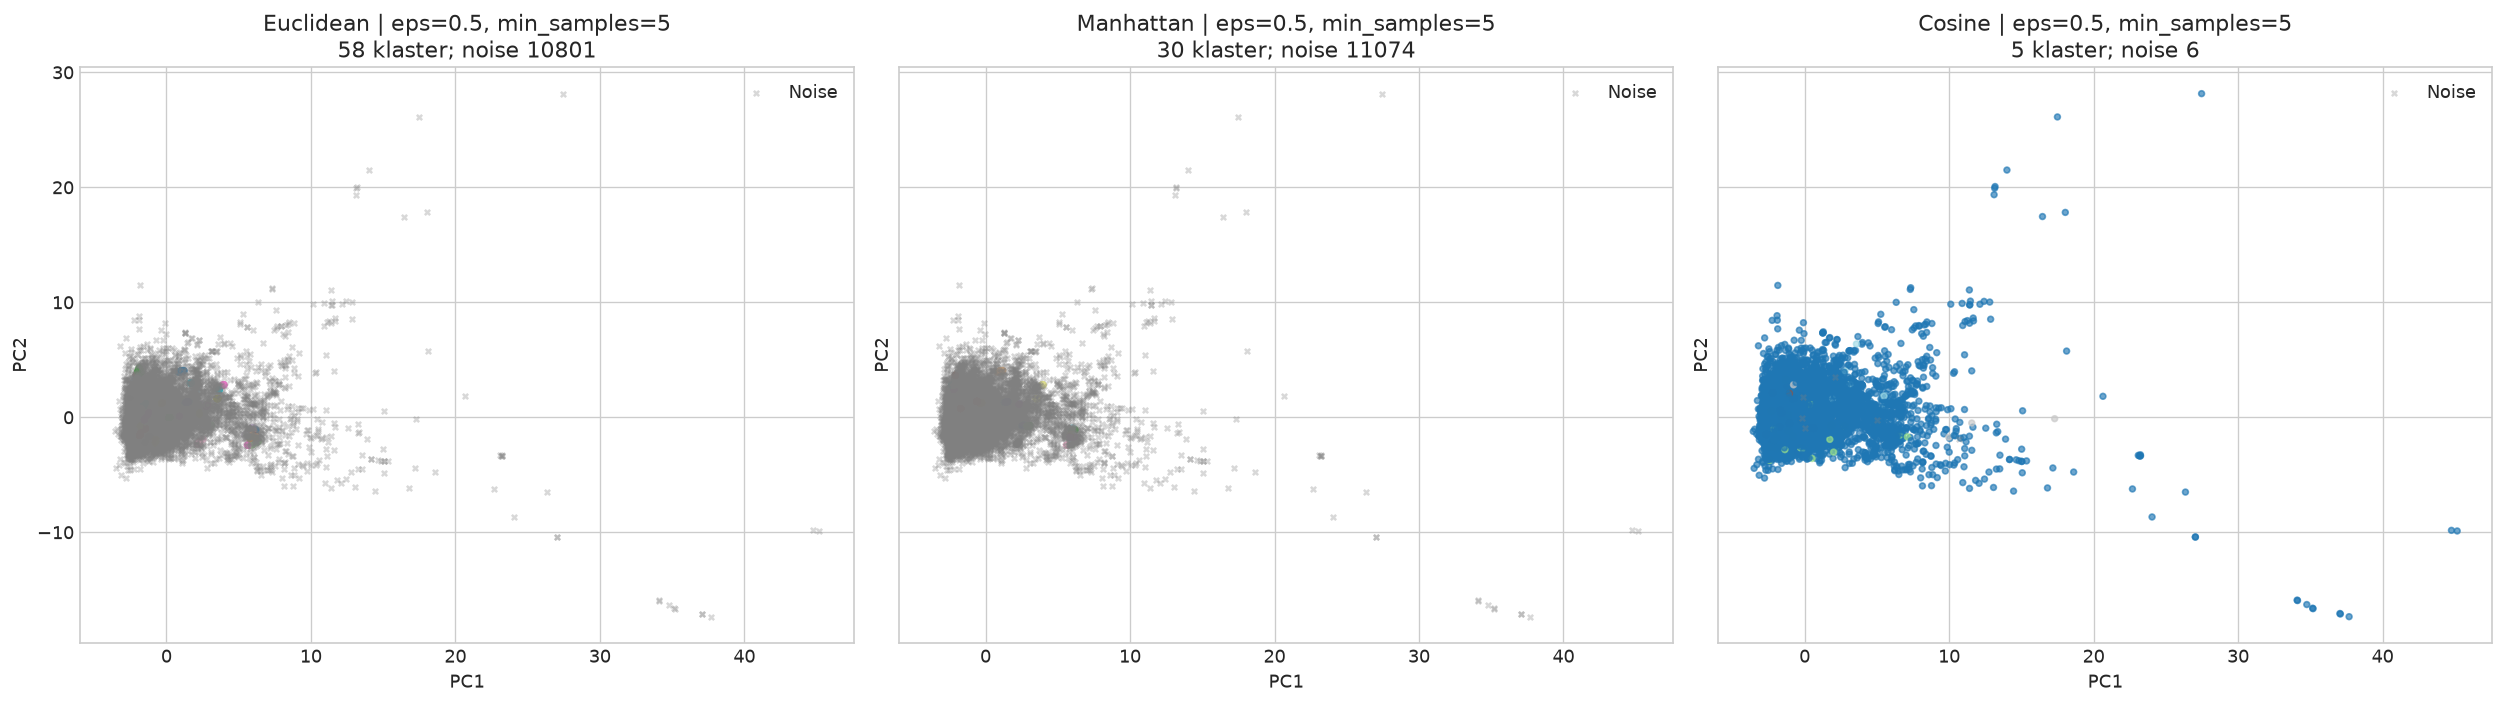

In [ ]:
# PCA dihitung sekali; seluruh model dilatih pada X_scaled.
pca = PCA(n_components=2, svd_solver='full', random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f'Variansi PC1 + PC2: {pca.explained_variance_ratio_.sum():.2%}')
fig, axes = plt.subplots(1, len(DISTANCE_METRICS), figsize=(7 * len(DISTANCE_METRICS), 6), squeeze=False, sharex=True, sharey=True)
for ax, metric in zip(axes.ravel(), DISTANCE_METRICS):
    model = models_by_metric[metric]
    node_labels = cluster_labels_by_metric[metric]
    mask = node_labels != -1
    if mask.any():
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=node_labels[mask], cmap='tab20', s=12, alpha=0.65)
    if (~mask).any():
        ax.scatter(X_pca[~mask, 0], X_pca[~mask, 1], color='gray', marker='x', s=10, alpha=0.3, label='Noise')
        ax.legend()
    ax.set(title=f'{metric.title()} | eps={model.eps}, min_samples={model.min_samples}\n{len(np.unique(node_labels[mask]))} klaster; noise {(~mask).sum()}', xlabel='PC1', ylabel='PC2')
plt.tight_layout()
plt.show()


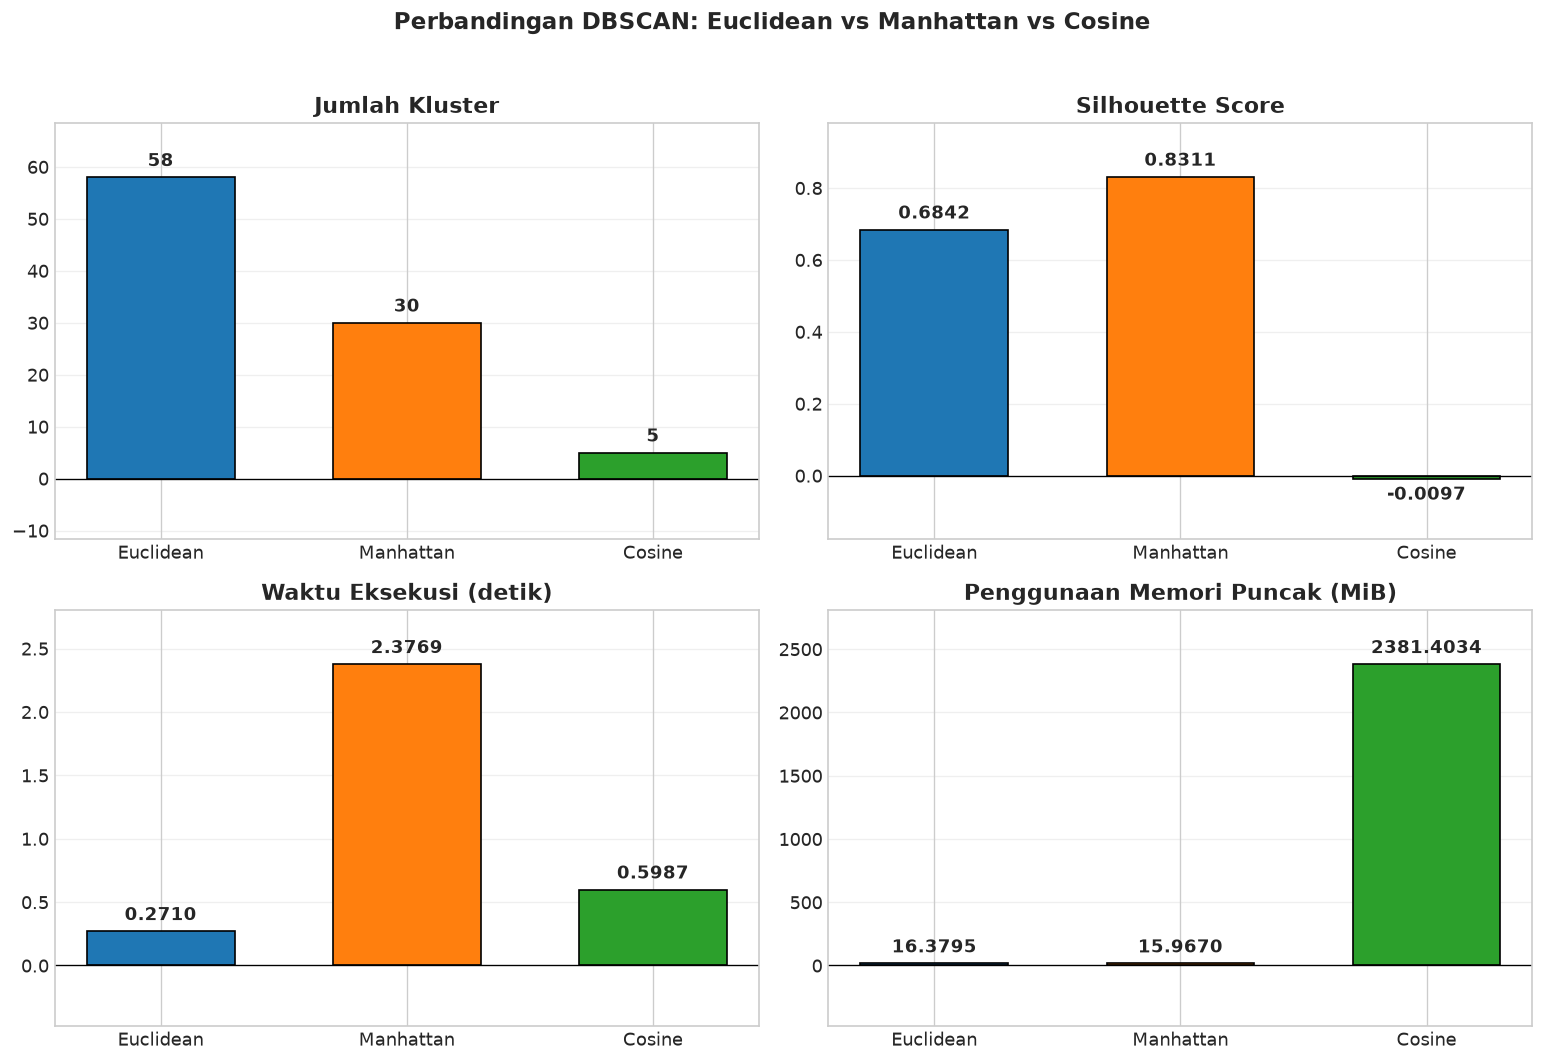

In [ ]:
# =======================================================================
# 7. DIAGRAM BATANG PERBANDINGAN EVALUASI & KINERJA
# =======================================================================
# Urutan dan warna mengikuti notebook referensi
nama = comparison_df["Distance Metric"].tolist()
warna = ["tab:blue", "tab:orange", "tab:green"]

panel = [
    ("Jumlah Kluster", "Jumlah Kluster", "{:.0f}"),
    ("Silhouette Score", "Silhouette Score", "{:.4f}"),
    ("Waktu Eksekusi (detik)", "Waktu Eksekusi (detik)", "{:.4f}"),
    ("Penggunaan Memori (MiB)", "Penggunaan Memori Puncak (MiB)", "{:.4f}"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (kolom, judul, fmt) in zip(axes.ravel(), panel):
    nilai = comparison_df[kolom].to_numpy(dtype=float)

    bars = ax.bar(
        nama,
        np.where(np.isfinite(nilai), nilai, 0),
        color=warna,
        edgecolor="black",
        width=0.6
    )

    ax.set_title(judul, fontweight="bold")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(axis="y", alpha=0.3)

    nilai_valid = nilai[np.isfinite(nilai)]
    if len(nilai_valid) > 0:
        batas = max(np.max(np.abs(nilai_valid)), 1e-9)
        ymin = min(0, np.min(nilai_valid)) - 0.20 * batas
        ymax = np.max(nilai_valid) + 0.18 * batas
        if np.isclose(ymin, ymax):
            ymax = ymin + 1
        ax.set_ylim(ymin, ymax)

    for bar, value in zip(bars, nilai):
        if np.isfinite(value):
            ax.annotate(
                fmt.format(value),
                (bar.get_x() + bar.get_width() / 2, value),
                ha="center",
                va="bottom" if value >= 0 else "top",
                xytext=(0, 4 if value >= 0 else -4),
                textcoords="offset points",
                fontweight="bold"
            )
        else:
            ax.annotate(
                "N/A",
                (bar.get_x() + bar.get_width() / 2, 0),
                ha="center",
                va="bottom",
                xytext=(0, 4),
                textcoords="offset points",
                fontweight="bold"
            )

fig.suptitle(
    "Perbandingan DBSCAN: Euclidean vs Manhattan vs Cosine",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [ ]:
# =======================================================================
# 8. INTERPRETASI HASIL PERBANDINGAN
# =======================================================================
print('INTERPRETASI HASIL PERBANDINGAN DBSCAN')
for _, row in comparison_df.iterrows():
    score = row['Silhouette Score']
    score_text = f'{score:.4f}' if np.isfinite(score) else 'N/A (jumlah klaster non-noise tidak memenuhi syarat)'
    print(f"{row['Distance Metric']}: {int(row['Jumlah Kluster'])} klaster, "
          f"{int(row['Noise'])} noise ({row['Noise (%)']:.2f}%), Silhouette = {score_text}")
print('Silhouette tiap baris memakai geometri metriknya sendiri; jumlah data non-noise dapat berbeda.')
print('Waktu fit tidak mencakup Silhouette. Memori merupakan peak tracked memory tracemalloc dalam MiB.')
print('PCA hanya untuk visualisasi; proses clustering memakai seluruh fitur setelah StandardScaler.')


INTERPRETASI HASIL PERBANDINGAN DBSCAN
Euclidean: 58 klaster, 10801 noise (94.50%), Silhouette = 0.6842
Manhattan: 30 klaster, 11074 noise (96.89%), Silhouette = 0.8311
Cosine: 5 klaster, 6 noise (0.05%), Silhouette = -0.0097
Silhouette tiap baris memakai geometri metriknya sendiri; jumlah data non-noise dapat berbeda.
Waktu fit tidak mencakup Silhouette. Memori merupakan peak tracked memory tracemalloc dalam MiB.
PCA hanya untuk visualisasi; proses clustering memakai seluruh fitur setelah StandardScaler.
